<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 3 · Sesión 1: De la Bernoulli a la regresión logística: odds, verosimilitud y Newton-Raphson</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: logit empírico, odds ratios, IRLS desde cero, Newton vs. gradiente, sklearn vs. statsmodels, separación y Firth</div>
</div>

## Objetivos de la sesión (2 horas)

1. Pasar de la **Bernoulli** a la **regresión logística**: odds, log-odds y función logística, con ejemplos sobre datos de crédito.
2. Interpretar **coeficientes y odds ratios** en lenguaje de riesgo.
3. Derivar la **log-verosimilitud, el gradiente y el Hessiano**, e implementar **Newton-Raphson (IRLS)** desde cero.
4. Comparar Newton-Raphson con el **descenso de gradiente** y entender la convergencia cuadrática.
5. Reconocer la **separación perfecta** y corregirla con la **regresión logística de Firth**.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 20 min | Bernoulli, odds, log-odds y logit empírico |
| 2 | 15 min | Función logística e interpretación de coeficientes |
| 3 | 35 min | Verosimilitud, gradiente, Hessiano y Newton-Raphson desde cero |
| 4 | 15 min | Newton vs. descenso de gradiente; statsmodels vs. scikit-learn |
| 5 | 25 min | Separación perfecta y regresión de Firth |
| 6 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

import warnings; warnings.filterwarnings("ignore")
import statsmodels.api as sm
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression
app = pd.read_csv(DATA / "hc_application_sintetico.csv").drop_duplicates()
app["EDAD"] = -app.DAYS_BIRTH / 365.25
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
app["EXT2"] = app.EXT_SOURCE_2.fillna(app.EXT_SOURCE_2.median())
print(app.shape, f"tasa de incumplimiento: {app.TARGET.mean():.2%}")

(60000, 32) tasa de incumplimiento: 7.98%


## 1. De la Bernoulli a los odds y log-odds
Para un cliente, $D \sim \text{Bernoulli}(p)$. Tres escalas para la misma información:

| Escala | Fórmula | Rango | Ejemplo con p = 8 % |
|---|---|---|---|
| Probabilidad | $p$ | [0, 1] | 0,08 |
| **Odds** | $p / (1-p)$ | [0, ∞) | 0,087 ("1 malo por cada 11,5 buenos") |
| **Log-odds (logit)** | $\ln(p/(1-p))$ | (−∞, ∞) | −2,44 |

En scoring se usan mucho los **odds buenos:malos** (la inversa): 11,5:1.

In [2]:
p = app.TARGET.mean()
print(f"p = {p:.4f} | odds malo = {p / (1 - p):.4f} | odds bueno:malo = {(1 - p) / p:.1f}:1 | log-odds = {np.log(p / (1 - p)):.3f}")
tab = app.groupby("NAME_INCOME_TYPE").TARGET.agg(n="size", p="mean")
tab["odds"] = tab.p / (1 - tab.p); tab["log_odds"] = np.log(tab.odds)
tab["odds_ratio_vs_Working"] = tab.odds / tab.loc["Working", "odds"]
tab.style.format({"p": "{:.2%}", "odds": "{:.4f}", "log_odds": "{:.3f}", "odds_ratio_vs_Working": "{:.2f}"})

p = 0.0798 | odds malo = 0.0868 | odds bueno:malo = 11.5:1 | log-odds = -2.445


,n,p,odds,log_odds,odds_ratio_vs_Working
NAME_INCOME_TYPE,,,,,
Commercial associate,14014,7.85%,0.0852,-2.463,0.78
Pensioner,10696,3.57%,0.0370,-3.296,0.34
State servant,4257,5.71%,0.0605,-2.804,0.55
Unemployed,33,6.06%,0.0645,-2.741,0.59
Working,31000,9.88%,0.1096,-2.211,1.00


### ¿Por qué modelar el log-odds como lineal? El **logit empírico**
Si agrupamos una variable en tramos y graficamos el log-odds observado de cada tramo, una relación aproximadamente **lineal** justifica la regresión logística con esa variable tal cual. Si no es lineal, necesitamos transformarla (WoE, splines; sesión 2 y 3).

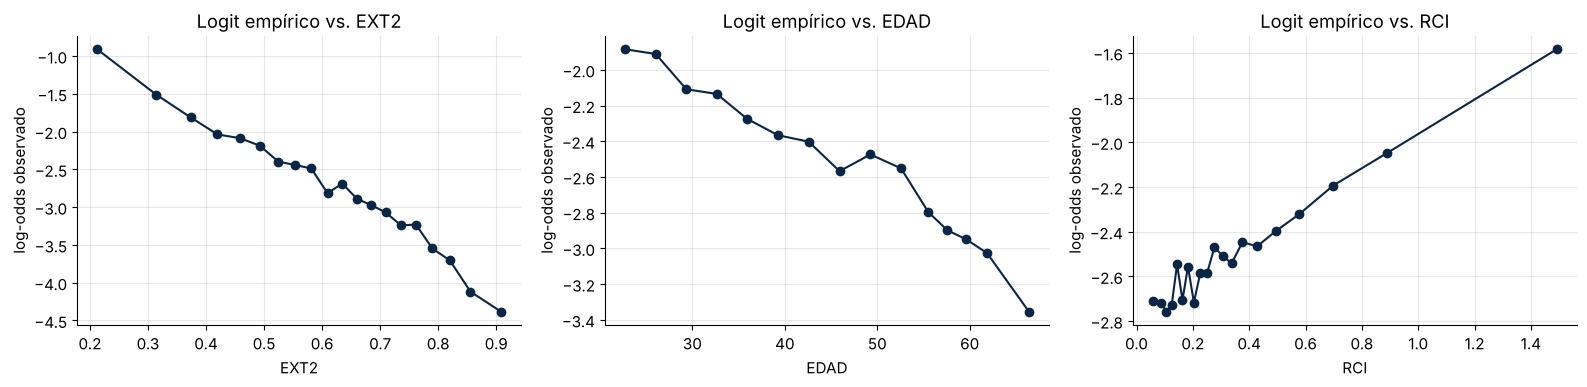

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, var, nb in zip(ax, ["EXT2", "EDAD", "RCI"], [20, 15, 20]):
    b = pd.qcut(app[var], nb, duplicates="drop")
    g = app.groupby(b, observed=True).agg(x=(var, "mean"), p=("TARGET", "mean"))
    a.plot(g.x, logit(g.p), "o-", color=AZUL)
    a.set_title(f"Logit empírico vs. {var}"); a.set_xlabel(var); a.set_ylabel("log-odds observado")
plt.tight_layout(); plt.show()

**Lectura:** `EXT2` tiene una relación casi lineal (decreciente) con el log-odds; `EDAD` también. `RCI` es **plana** hasta ~0,4 y luego crece: no es lineal. Meterla cruda en una logística subestimará su efecto en los valores altos.

## 2. La función logística e interpretación de coeficientes
$$p(x) = \frac{1}{1 + e^{-(\beta_0 + \beta^\top x)}} \qquad \Longleftrightarrow \qquad \ln\frac{p}{1-p} = \beta_0 + \beta^\top x$$

- $\beta_j$: cambio en el **log-odds** por una unidad de $x_j$, manteniendo lo demás constante.
- $e^{\beta_j}$: **odds ratio**, el multiplicador de los odds.
- El efecto sobre la **probabilidad** no es constante: $\partial p / \partial x_j = \beta_j\, p(1-p)$, máximo cuando $p = 0{,}5$.

In [4]:
X = sm.add_constant(app[["EXT2", "EDAD"]].assign(EXT2=lambda d: d.EXT2 * 10))      # EXT2 en décimas para interpretar
m = sm.Logit(app.TARGET, X).fit(disp=0)
print(m.params.round(4).to_string())
or_ext = np.exp(m.params["EXT2"]); or_edad10 = np.exp(10 * m.params["EDAD"])
print(f"\n+0,1 en EXT_SOURCE_2 multiplica los odds de incumplir por {or_ext:.3f} ({(or_ext - 1):+.1%})")
print(f"+10 años de edad multiplican los odds por {or_edad10:.3f} ({(or_edad10 - 1):+.1%})")
# efecto marginal promedio en probabilidad
ame = m.get_margeff(at="overall").summary_frame()
print("\nEfecto marginal promedio sobre la probabilidad (por unidad):"); print(ame[["dy/dx", "Std. Err."]].round(5).to_string())

const    0.8183
EXT2    -0.4227
EDAD    -0.0226

+0,1 en EXT_SOURCE_2 multiplica los odds de incumplir por 0.655 (-34.5%)
+10 años de edad multiplican los odds por 0.798 (-20.2%)

Efecto marginal promedio sobre la probabilidad (por unidad):
       dy/dx  Std. Err.
EXT2 -0.0290     0.0006
EDAD -0.0015     0.0001


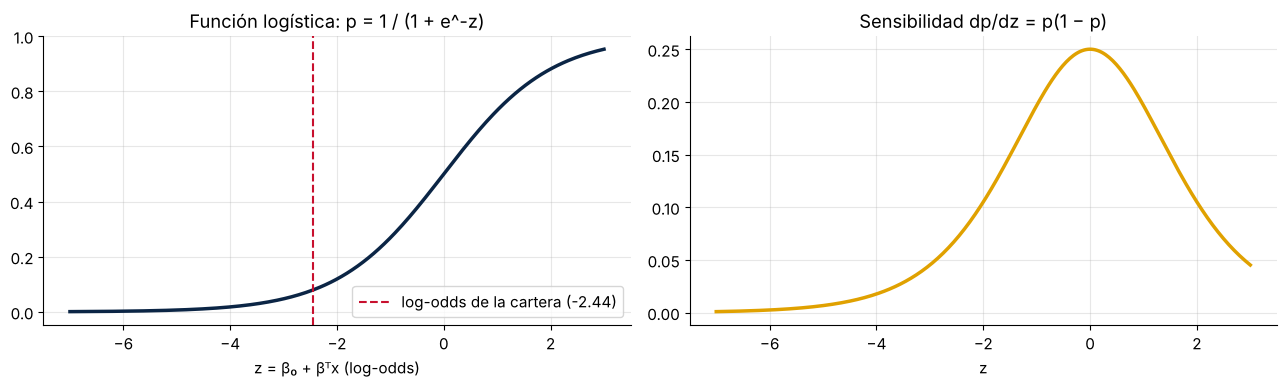

In [5]:
z = np.linspace(-7, 3, 300)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(z, expit(z), color=AZUL, lw=2.5); ax[0].set_title("Función logística: p = 1 / (1 + e^-z)"); ax[0].set_xlabel("z = β₀ + βᵀx (log-odds)")
ax[0].axvline(np.log(p / (1 - p)), color=ROJO, ls="--", label=f"log-odds de la cartera ({np.log(p / (1 - p)):.2f})"); ax[0].legend()
ax[1].plot(z, expit(z) * (1 - expit(z)), color=ORO, lw=2.5); ax[1].set_title("Sensibilidad dp/dz = p(1 − p)"); ax[1].set_xlabel("z")
plt.tight_layout(); plt.show()

**Lectura de negocio:** en una cartera con PD baja (z ≈ −2,4), un mismo cambio en el score mueve poco la probabilidad absoluta, pero mucho los **odds relativos**. Por eso los scorecards trabajan en escala de odds (puntos para duplicar los odds, sesión 4).

## 3. Verosimilitud, gradiente, Hessiano y Newton-Raphson desde cero
Con $p_i = \sigma(x_i^\top\beta)$:
$$\ell(\beta) = \sum_i \left[y_i \, x_i^\top\beta - \ln(1 + e^{x_i^\top\beta})\right]$$
$$\nabla \ell(\beta) = X^\top (y - p) \qquad H(\beta) = -X^\top W X, \quad W = \text{diag}(p_i(1-p_i))$$

**Newton-Raphson:** $\beta^{(t+1)} = \beta^{(t)} - H^{-1}\nabla\ell = \beta^{(t)} + (X^\top W X)^{-1} X^\top (y - p)$.

Reescrito, es una regresión por **mínimos cuadrados ponderados iterados (IRLS)** con respuesta de trabajo $z = X\beta + W^{-1}(y - p)$.

In [6]:
def newton_raphson(X, y, tol=1e-10, max_iter=25, verbose=True):
    beta = np.zeros(X.shape[1])
    hist = []
    for t in range(max_iter):
        eta = X @ beta
        p = expit(eta)
        ll = np.sum(y * eta - np.logaddexp(0, eta))
        grad = X.T @ (y - p)
        W = p * (1 - p)
        H = X.T @ (X * W[:, None])                       # = -Hessiano
        paso = np.linalg.solve(H, grad)
        beta = beta + paso
        hist.append((t, ll, np.linalg.norm(grad), np.abs(paso).max()))
        if np.abs(paso).max() < tol:
            break
    se = np.sqrt(np.diag(np.linalg.inv(H)))
    h = pd.DataFrame(hist, columns=["iter", "logLik", "norma_gradiente", "max_paso"])
    if verbose: display(h.style.format({"logLik": "{:.6f}", "norma_gradiente": "{:.2e}", "max_paso": "{:.2e}"}))
    return beta, se, h

Xm = np.column_stack([np.ones(len(app)), app.EXT2 * 10, app.EDAD, app.RCI])
y = app.TARGET.values
beta, se, hist = newton_raphson(Xm, y)
ref = sm.Logit(y, Xm).fit(disp=0)
pd.DataFrame({"beta_NR": beta, "beta_statsmodels": ref.params, "SE_NR": se, "SE_statsmodels": ref.bse},
             index=["const", "EXT2 (décimas)", "EDAD", "RCI"]).style.format("{:.6f}")

,iter,logLik,norma_gradiente,max_paso
0,0,-41588.830834,1.17e+06,7.45e-01
1,1,-17518.047602,2.31e+05,5.21e-01
2,2,-15276.196399,5.85e+04,5.95e-01
3,3,-14950.916825,1.08e+04,1.68e-01
4,4,-14935.996141,5.95e+02,9.66e-03
5,5,-14935.950551,1.96e+00,3.13e-05
6,6,-14935.950550,2.08e-05,3.34e-10
7,7,-14935.950550,3.77e-11,4.96e-16


,beta_NR,beta_statsmodels,SE_NR,SE_statsmodels
const,0.549198,0.549198,0.065464,0.065464
EXT2 (décimas),-0.413687,-0.413687,0.008608,0.008608
EDAD,-0.023207,-0.023207,0.001194,0.001194
RCI,0.593624,0.593624,0.034686,0.034686


**Convergencia cuadrática:** la norma del gradiente cae de forma **cuadrática** (el número de dígitos correctos se duplica en cada iteración cerca del óptimo). En 6-7 iteraciones se alcanza la precisión de máquina.

## 4. Newton vs. descenso de gradiente; statsmodels vs. scikit-learn
El descenso de gradiente usa solo la primera derivada: $\beta^{(t+1)} = \beta^{(t)} + \eta \, \nabla\ell / n$. Es más barato por iteración, pero necesita muchas más iteraciones y es sensible a la escala de las variables.

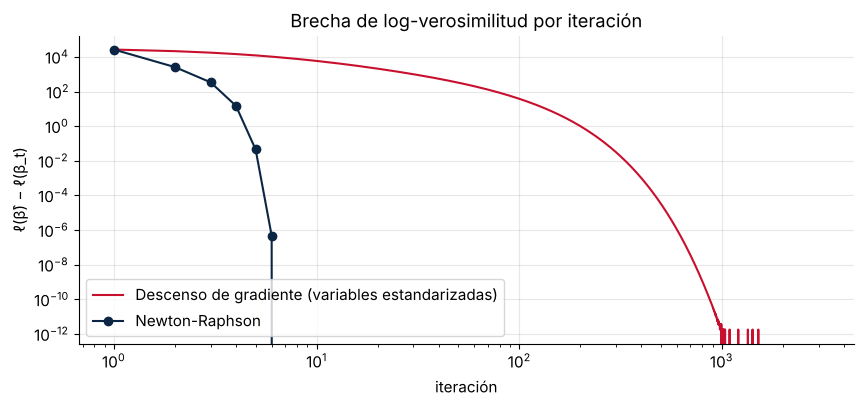

In [7]:
def descenso_gradiente(X, y, lr=0.5, iters=3000):
    Xs = (X - np.r_[0, X[:, 1:].mean(0)]) / np.r_[1, X[:, 1:].std(0)]     # estandarizar ayuda mucho
    b = np.zeros(X.shape[1]); ll = []
    for _ in range(iters):
        eta = Xs @ b; b += lr * Xs.T @ (y - expit(eta)) / len(y)
        ll.append(np.sum(y * eta - np.logaddexp(0, eta)))
    return np.array(ll)
ll_gd = descenso_gradiente(Xm, y)
plt.figure(figsize=(10, 4))
plt.plot(np.arange(1, len(ll_gd) + 1), ref.llf - ll_gd, color=ROJO, label="Descenso de gradiente (variables estandarizadas)")
plt.plot(hist.iter + 1, ref.llf - hist.logLik, "o-", color=AZUL, label="Newton-Raphson")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("iteración"); plt.ylabel("ℓ(β̂) − ℓ(β_t)"); plt.legend(); plt.title("Brecha de log-verosimilitud por iteración"); plt.show()

In [8]:
# ¡Cuidado! scikit-learn regulariza por defecto (penalty='l2', C=1.0)
sk_def = LogisticRegression(max_iter=2000).fit(Xm[:, 1:], y)
sk_none = LogisticRegression(C=1e12, max_iter=5000).fit(Xm[:, 1:], y)        # C enorme = sin penalización (portable entre versiones)
pd.DataFrame({"statsmodels (MLE)": ref.params[1:], "sklearn por defecto (L2, C=1)": sk_def.coef_[0], "sklearn sin penalización (C → ∞)": sk_none.coef_[0]},
             index=["EXT2 (décimas)", "EDAD", "RCI"]).style.format("{:.5f}")

,statsmodels (MLE),"sklearn por defecto (L2, C=1)",sklearn sin penalización (C → ∞)
EXT2 (décimas),-0.41369,-0.41366,-0.41368
EDAD,-0.02321,-0.02321,-0.02321
RCI,0.59362,0.59300,0.59371


> **Lección práctica:** `LogisticRegression()` de scikit-learn **no es** el estimador de máxima verosimilitud: aplica una penalización L2 con C = 1. Con muchos datos la diferencia es pequeña, pero con pocos datos o variables en escalas grandes puede ser importante. Para inferencia (errores estándar, p-valores) usa `statsmodels`; para predicción con regularización, `scikit-learn`.

## 5. Separación perfecta y regresión logística de Firth
Si una variable (o combinación) separa perfectamente buenos de malos, el MLE **no existe**: la verosimilitud crece sin límite cuando $|\beta| \to \infty$. Ocurre con muestras pequeñas, eventos raros o categorías con 0 malos (p. ej., un segmento nuevo).

**Firth (1993)** penaliza la verosimilitud con el prior de Jeffreys:
$$\ell^*(\beta) = \ell(\beta) + \tfrac{1}{2}\ln|I(\beta)|$$
Equivale a modificar el score: $U^*(\beta) = X^\top(y - p + h \odot (\tfrac{1}{2} - p))$, donde $h$ son los *leverages* (diagonal de la matriz sombrero). Da coeficientes **finitos** y reduce el sesgo de primer orden del MLE en muestras pequeñas.

In [9]:
def firth_logit(X, y, max_iter=100, tol=1e-8):
    b = np.zeros(X.shape[1])
    for _ in range(max_iter):
        p = expit(X @ b); W = p * (1 - p)
        I = X.T @ (X * W[:, None])
        Iinv = np.linalg.inv(I)
        h = np.einsum("ij,jk,ik->i", X * np.sqrt(W)[:, None], Iinv, X * np.sqrt(W)[:, None])   # leverages
        U = X.T @ (y - p + h * (0.5 - p))
        paso = Iinv @ U
        b = b + paso
        if np.abs(paso).max() < tol: break
    return b, np.sqrt(np.diag(Iinv))

# Segmento nuevo pequeño: 40 clientes, ninguno con "historial negativo" incumplió -> separación casi perfecta
rng = np.random.default_rng(3)
n = 40
hist_neg = rng.integers(0, 2, n)
y_s = np.where(hist_neg == 1, (rng.random(n) < 0.45).astype(int), 0)                            # los malos solo aparecen con historial negativo
Xs = np.column_stack([np.ones(n), hist_neg])
print(pd.crosstab(hist_neg, y_s, rownames=["historial_negativo"], colnames=["incumple"]))
try:
    r = sm.Logit(y_s, Xs).fit(disp=0, maxiter=100)
    print(f"\nMLE (statsmodels): beta = {r.params.round(2)}, SE = {r.bse.round(1)}  <- coeficientes y errores enormes: no converge a un valor finito")
except Exception as e:
    print("MLE falla:", type(e).__name__, e)
bf, sef = firth_logit(Xs, y_s)
print(f"Firth: beta = {bf.round(3)}, SE = {sef.round(3)}  ->  odds ratio = {np.exp(bf[1]):.1f}, finito y utilizable")

incumple             0  1
historial_negativo       
0                   21  0
1                   12  7

MLE (statsmodels): beta = [-26.04  25.5 ], SE = [98355.9 98355.9]  <- coeficientes y errores enormes: no converge a un valor finito
Firth: beta = [-3.761  3.25 ], SE = [1.464 1.539]  ->  odds ratio = 25.8, finito y utilizable


/usr/local/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


**Cuándo usar Firth:** muestras pequeñas, eventos raros (carteras de bajo incumplimiento, segmentos nuevos), variables dummy con celdas vacías. En Python se implementa en pocas líneas (arriba) o con el paquete `firthlogist`; en R, `logistf`.

**Otras alternativas a la separación:** agrupar categorías (WoE, sesión 3), regularización L2 (sesión 2) o un prior bayesiano (Módulo 6).

## 6. Ejercicios
1. Agrega `RCI²` al modelo. ¿Mejora la log-verosimilitud? ¿Coincide con lo que mostraba el logit empírico?
2. Modifica `newton_raphson` para que imprima también el número de condición de $X^\top W X$ en cada iteración.
3. Ejecuta el descenso de gradiente **sin** estandarizar. ¿Cuántas iteraciones necesita?
4. En el ejemplo de separación, aumenta n a 400. ¿Cómo cambia la diferencia entre MLE y Firth?